# Sequential Modelling with CNNN + LSTM, GRU, and RNN

## 1. Environment Setup

In this section, we import the libraries required for the experiment.

We will use:
- PyTorch for building and training the deep learning models.
- TensorFlow/Keras only to download the MNIST dataset.
- NumPy for generating the moving-digit sequences.
- Matplotlib for visualising the dataset and results.
- Scikit-learn for the confusion matrix.

In [1]:
import os
import time
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from tensorflow.keras.datasets import mnist
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
OUTPUT_DIR = "/content/sequence_model_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

Using device: cuda


## 2. Dataset Preparation

We will download MNIST, which contains handwritten digit images.

Each original image is 28×28 pixels. We will place each digit on a larger 64×64 black canvas.

We will then move the digit across the canvas over 16 frames.

Each sequence will have one of four labels:
- 0: Right
- 1: Left
- 2: Down
- 3: Up

We will generate separate training, validation and testing datasets.

The MNIST training images will be used to generate training sequences. The original MNIST test images will be divided between our validation and test sequences.

In [2]:
# Download MNIST
(x_train_mnist, _), (x_test_mnist, _) = mnist.load_data()

print("Training MNIST images:", x_train_mnist.shape)
print("Testing MNIST images:", x_test_mnist.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training MNIST images: (60000, 28, 28)
Testing MNIST images: (10000, 28, 28)


### 2.1 Generate Moving MNIST Sequences

The function below creates sequences of 16 frames.

For each sequence:
1. Randomly select an MNIST digit.
2. Assign a movement direction.
3. Randomly select its starting position and movement distance.
4. Generate 16 images showing the digit moving.
5. Store the corresponding direction label.

We use balanced direction labels so that each movement class has approximately the same number of samples.

In [3]:
CANVAS_SIZE = 64
DIGIT_SIZE = 28
SEQUENCE_LENGTH = 16
MAX_DISPLACEMENT = 14
CLASS_NAMES = ["Right", "Left", "Down", "Up"]

def generate_moving_sequences(source_images, n_sequences, seed):
    rng = np.random.default_rng(seed)
    max_position = CANVAS_SIZE - DIGIT_SIZE

    # Generate approximately balanced labels
    labels = np.tile(
        np.arange(4),
        int(np.ceil(n_sequences / 4))
    )[:n_sequences]
    rng.shuffle(labels)

    # Store sequences as uint8 to reduce memory consumption
    sequences = np.zeros(
        (n_sequences, SEQUENCE_LENGTH, CANVAS_SIZE, CANVAS_SIZE),
        dtype=np.uint8
    )

    for i in range(n_sequences):
        # Select a random handwritten digit
        digit = source_images[
            rng.integers(0, len(source_images))
        ]

        # Random movement distance
        displacement = int(
            rng.integers(10, MAX_DISPLACEMENT + 1)
        )

        # Choose a common starting-position range for all directions.
        # This reduces the possibility of the model learning direction
        # from the starting position alone.
        start_low = MAX_DISPLACEMENT
        start_high = max_position - MAX_DISPLACEMENT

        x0 = int(rng.integers(start_low, start_high + 1))
        y0 = int(rng.integers(start_low, start_high + 1))

        # Set the movement direction
        direction = labels[i]
        dx, dy = 0, 0
        if direction == 0:       # Right
            dx = displacement
        elif direction == 1:     # Left
            dx = -displacement
        elif direction == 2:     # Down
            dy = displacement
        elif direction == 3:     # Up
            dy = -displacement

        # Generate the 16 frames
        for t in range(SEQUENCE_LENGTH):
            progress = t / (SEQUENCE_LENGTH - 1)
            x = int(round(x0 + dx * progress))
            y = int(round(y0 + dy * progress))
            canvas = np.zeros(
                (CANVAS_SIZE, CANVAS_SIZE),
                dtype=np.uint8
            )
            canvas[
                y:y + DIGIT_SIZE,
                x:x + DIGIT_SIZE
            ] = digit

            sequences[i, t] = canvas
    return sequences, labels.astype(np.int64)

# Generate the three dataset splits
X_train, y_train = generate_moving_sequences(
    x_train_mnist,
    n_sequences=1200,
    seed=SEED
)

X_val, y_val = generate_moving_sequences(
    x_test_mnist[:5000],
    n_sequences=300,
    seed=SEED + 1
)

X_test, y_test = generate_moving_sequences(
    x_test_mnist[5000:],
    n_sequences=300,
    seed=SEED + 2
)

print("Training sequences:", X_train.shape)
print("Validation sequences:", X_val.shape)
print("Testing sequences:", X_test.shape)
print("\nTraining class distribution:")

for i, name in enumerate(CLASS_NAMES):
    print(name, ":", np.sum(y_train == i))

Training sequences: (1200, 16, 64, 64)
Validation sequences: (300, 16, 64, 64)
Testing sequences: (300, 16, 64, 64)

Training class distribution:
Right : 300
Left : 300
Down : 300
Up : 300


We have converted individual MNIST images into short videos. Each video contains 16 frames, and its label represents the directions in which the digit moves.

## 3. Visualising the Dataset

Before training, we should inspect some generated sequences.

We will display the 16 frames of one sequence to verify that the digit moves correctly and that the assigned direction label makes sense.

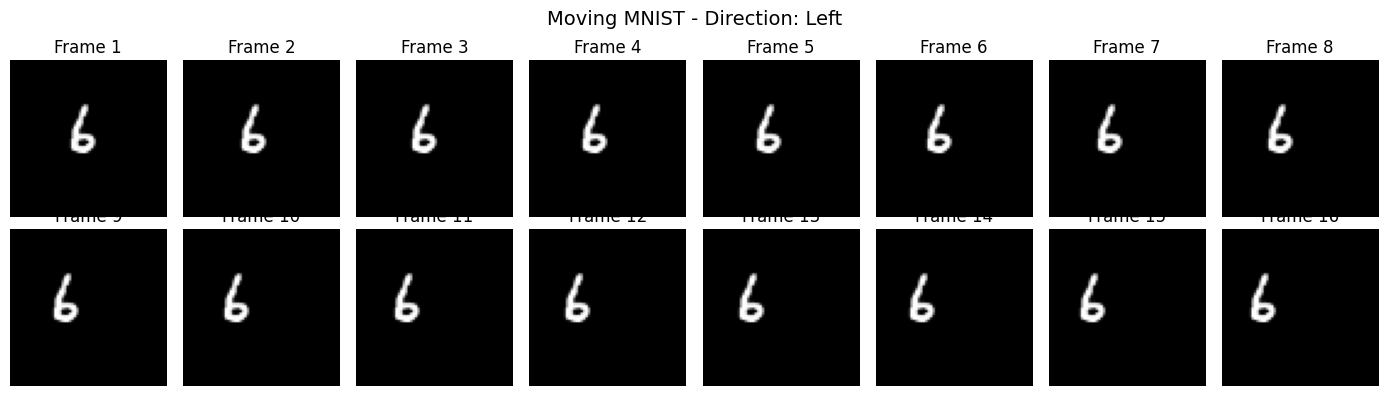

In [4]:
sample_index = 0
sample_sequence = X_train[sample_index]
sample_label = y_train[sample_index]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(sample_sequence[i], cmap="gray")
    ax.set_title(f"Frame {i + 1}")
    ax.axis("off")

plt.suptitle(
    f"Moving MNIST - Direction: {CLASS_NAMES[sample_label]}",
    fontsize=14
)
plt.tight_layout()
plt.show()

## 4. Dataset and DataLoader Preparation

PyTorch expects data to be organised into tensors.

Our data currently has this shape:

(N, 16, 64, 64)

Where:
- N is the number of sequences.
- 16 is the number of frames.
- 64 × 64 represents the image dimensions.

We will create a custom PyTorch Dataset.

An important requirement is that we want to experiment with 4, 8 and 16 sampled frames.

Therefore, our Dataset class will select the required number of frames from each original 16-frame sequence.

In [5]:
class MovingMNISTDataset(Dataset):
    def __init__(self, sequences, labels, num_frames=8):
        self.sequences = torch.from_numpy(sequences)
        self.labels = torch.from_numpy(labels)

        # Select evenly spaced frames
        frame_indices = np.linspace(
            0,
            SEQUENCE_LENGTH - 1,
            num=num_frames
        )
        frame_indices = np.round(frame_indices).astype(np.int64)
        self.frame_indices = torch.tensor(frame_indices)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        # Select the required frames
        frames = self.sequences[index].index_select(
            0,
            self.frame_indices
        )

        # Convert pixel values to float and normalise to [0, 1]
        frames = frames.float() / 255.0
        # Add the channel dimension
        # Shape: (T, 1, 64, 64)
        frames = frames.unsqueeze(1)
        label = self.labels[index]
        return frames, label

# Create DataLoaders
BATCH_SIZE = 32
def create_dataloaders(num_frames):
    train_dataset = MovingMNISTDataset(
        X_train, y_train, num_frames
    )
    val_dataset = MovingMNISTDataset(
        X_val, y_val, num_frames
    )
    test_dataset = MovingMNISTDataset(
        X_test, y_test, num_frames
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    return train_loader, val_loader, test_loader

# Test the DataLoader using 8 frames
train_loader, val_loader, test_loader = create_dataloaders(8)
frames, labels = next(iter(train_loader))

print("Batch frame shape:", frames.shape)
print("Batch label shape:", labels.shape)

Batch frame shape: torch.Size([32, 8, 1, 64, 64])
Batch label shape: torch.Size([32])


The dimensions mean:

[batch_size, number_of_frames, channels, height, width]

## 5. Model Architecture

We will implement a CNN + recurrent neural network architecture.

The architecture has three main components:

1. CNN feature extractor:
   Processes each individual frame and extracts visual features.

2. Recurrent network:
   Receives the sequence of extracted features and learns temporal relationships between frames.

3. Classification head:
   Uses the final temporal representation to predict one of the four movement directions.

We will create one model class that supports:
- LSTM
- GRU
- Plain RNN

This allows us to keep the CNN and classification head consistent while replacing only the recurrent layer.

In [6]:
# CNN Feature Extractor
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.output_features = 32 * 4 * 4

    def forward(self, x):
        x = self.network(x)
        x = x.flatten(start_dim=1)
        return x

# CNN + Recurrent Model
class SequenceClassifier(nn.Module):
    def __init__(
        self,
        cell_type="LSTM",
        hidden_size=96,
        num_classes=4
    ):
        super().__init__()
        self.cell_type = cell_type
        self.encoder = CNNEncoder()
        feature_size = self.encoder.output_features

        # Select the recurrent architecture
        if cell_type == "LSTM":
            self.temporal = nn.LSTM(
                input_size=feature_size,
                hidden_size=hidden_size,
                batch_first=True
            )
        elif cell_type == "GRU":
            self.temporal = nn.GRU(
                input_size=feature_size,
                hidden_size=hidden_size,
                batch_first=True
            )
        elif cell_type == "RNN":
            self.temporal = nn.RNN(
                input_size=feature_size,
                hidden_size=hidden_size,
                nonlinearity="tanh",
                batch_first=True
            )
        else:
            raise ValueError("Unsupported recurrent unit")

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
        self.cnn_is_frozen = False

    def set_encoder_trainable(self, trainable):
        self.cnn_is_frozen = not trainable
        for parameter in self.encoder.parameters():
            parameter.requires_grad = trainable

    def forward(self, frames):

        batch_size, num_frames, channels, height, width = frames.shape

        # Combine batch and frame dimensions
        frames = frames.reshape(
            batch_size * num_frames,
            channels,
            height,
            width
        )

        # Extract visual features
        if self.cnn_is_frozen:
            with torch.no_grad():
                features = self.encoder(frames)

        else:
            features = self.encoder(frames)

        # Restore the sequence dimension
        features = features.reshape(
            batch_size,
            num_frames,
            -1
        )

        # Process the sequence
        temporal_output = self.temporal(features)

        # LSTM and GRU return a tuple.
        # Plain RNN returns a tensor.
        if isinstance(temporal_output, tuple):
            temporal_output = temporal_output[0]

        # Use the output from the final frame
        final_output = temporal_output[:, -1, :]

        # Predict the movement direction
        predictions = self.classifier(final_output)

        return predictions


# Test the LSTM architecture
model = SequenceClassifier(
    cell_type="LSTM",
    hidden_size=96
).to(DEVICE)
sample_frames, _ = next(iter(train_loader))
sample_frames = sample_frames.to(DEVICE)
output = model(sample_frames)

print("Prediction output shape:", output.shape)

Prediction output shape: torch.Size([32, 4])


The model outputs four values for each sequence, corresponding to the four possible directions.

How the architecture works:
1) Input sequence: 8 frames x 64 x 64 pixels
2) CNN feature extractor: Extracts spatial features from every frame.
3) LSTM / GRU / RNN: Learns relationships between consecutive frames.
4) Classification head: Predicts one of four movement directions.

## 6. Training and Evaluation Functions

Before training the models, we need functions to:
- Train the model for one epoch.
- Evaluate the model on validation or test data.
- Calculate loss and classification accuracy.

We use CrossEntropyLoss because this is a multi-class classification problem.

We also use gradient clipping to reduce the risk of exploding gradients during recurrent network training.

In [7]:
# Train for one epoch
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    # Keep the frozen CNN in evaluation mode.
    # This prevents its BatchNorm running statistics from changing.
    if model.cnn_is_frozen:
        model.encoder.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for frames, labels in loader:
        frames = frames.to(
            DEVICE,
            non_blocking=True
        )
        labels = labels.to(
            DEVICE,
            non_blocking=True
        )
        optimizer.zero_grad(set_to_none=True)
        outputs = model(frames)
        loss = criterion(outputs, labels)
        loss.backward()

        # Gradient clipping
        trainable_parameters = [
            p for p in model.parameters()
            if p.requires_grad
        ]

        nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=1.0
        )

        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        predictions = torch.argmax(outputs, dim=1)
        correct_predictions += (
            predictions == labels
        ).sum().item()
        total_samples += labels.size(0)

    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples
    return average_loss, accuracy

# Evaluation function
@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    all_labels = []
    all_predictions = []

    for frames, labels in loader:
        frames = frames.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(frames)
        loss = criterion(outputs, labels)
        predictions = torch.argmax(outputs, dim=1)
        total_loss += loss.item() * labels.size(0)
        correct_predictions += (
            predictions == labels
        ).sum().item()
        total_samples += labels.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples
    return (
        average_loss,
        accuracy,
        all_labels,
        all_predictions
    )

## 7. Two-Stage Training

We will use two training stages.

Stage 1: Frozen CNN
- Freeze the CNN parameters.
- Train the recurrent network and classification head.
- Use a learning rate of 0.001.

Stage 2: Fine-tuning
- Unfreeze the CNN parameters.
- Train the entire model.
- Use a smaller learning rate of 0.0001.

We use the best validation-loss checkpoint from the frozen stage as the starting point for fine-tuning.

We will select the best validation checkpoint from the fine-tuning stage for final testing.

In [8]:
# Fit one training stage
def fit_stage(
    model,
    train_loader,
    val_loader,
    epochs,
    learning_rate,
    stage_name
):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=learning_rate,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    print(f"\nStarting {stage_name}")
    for epoch in range(epochs):
        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )
        val_loss, val_accuracy, _, _ = evaluate(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        # Save the best model based on validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

    # Restore the best checkpoint from this stage
    model.load_state_dict(best_state)

    return history

### 7.1 Complete Model Training

The function below performs the entire training process.

It will:
1. Initialise the selected recurrent architecture.
2. Freeze the CNN.
3. Train the model.
4. Unfreeze the CNN.
5. Fine-tune the entire model.
6. Evaluate the best model on the test set.
7. Record training time and parameter count.

The recorded training time covers both training stages, including their validation passes.

In [9]:
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
    )

def run_experiment(
    cell_type,
    num_frames,
    frozen_epochs=3,
    finetune_epochs=4
):

    # Make initialisation reproducible between experiments
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    print("\n" + "=" * 60)

    print(
        f"Experiment: {cell_type} | "
        f"Frames: {num_frames}"
    )

    print("=" * 60)

    # Create DataLoaders
    train_loader, val_loader, test_loader = (
        create_dataloaders(num_frames)
    )

    # Initialise model
    model = SequenceClassifier(
        cell_type=cell_type,
        hidden_size=96
    ).to(DEVICE)
    parameter_count = count_parameters(model)

    # Stage 1: Freeze CNN
    model.set_encoder_trainable(False)
    start_time = time.perf_counter()
    frozen_history = fit_stage(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=frozen_epochs,
        learning_rate=1e-3,
        stage_name="CNN Frozen Training"
    )

    # Stage 2: Fine-tune entire model
    model.set_encoder_trainable(True)
    finetune_history = fit_stage(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=finetune_epochs,
        learning_rate=1e-4,
        stage_name="Fine-tuning"
    )

    training_time = time.perf_counter() - start_time


    # Final test evaluation
    test_loss, test_accuracy, y_true, y_pred = evaluate(
        model,
        test_loader
    )

    result = {
        "recurrent_unit": cell_type,
        "frames": num_frames,
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "training_time_seconds": training_time,
        "total_parameters": parameter_count
    }

    history = {
        "frozen": frozen_history,
        "fine_tune": finetune_history
    }

    print("\nFinal results")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")
    print(f"Parameters: {parameter_count:,}")
    return model, result, history

## 8. Experimental Comparison

We will run five experiments.

First, we compare LSTM, GRU and plain RNN using eight frames.

Next, we compare LSTM models using 4, 8 and 16 frames.

For every experiment, we use the same training and validation datasets, model structure, hidden size and two-stage training procedure.

This helps us make a fair comparison between the different configurations.

In [10]:
# Training configuration
FROZEN_EPOCHS = 3
FINETUNE_EPOCHS = 4

# Experiment configurations
experiment_specs = [
    ("LSTM", 8),
    ("GRU", 8),
    ("RNN", 8),
    ("LSTM", 4),
    ("LSTM", 16)
]

# Store trained models, results and histories
trained_models = {}
all_results = []
all_histories = {}

# Run experiments
for cell_type, num_frames in experiment_specs:
    experiment_name = f"{cell_type}_{num_frames}"
    model, result, history = run_experiment(
        cell_type=cell_type,
        num_frames=num_frames,
        frozen_epochs=FROZEN_EPOCHS,
        finetune_epochs=FINETUNE_EPOCHS
    )
    trained_models[experiment_name] = model
    all_results.append(result)
    all_histories[experiment_name] = history

# Create results DataFrame
results_df = pd.DataFrame(all_results)
results_df["test_accuracy_percent"] = (
    results_df["test_accuracy"] * 100
)

results_df["training_time_minutes"] = (
    results_df["training_time_seconds"] / 60
)

results_df = results_df[
    [
        "recurrent_unit",
        "frames",
        "test_accuracy_percent",
        "test_loss",
        "training_time_seconds",
        "training_time_minutes",
        "total_parameters"
    ]
]

print("\nEXPERIMENT RESULTS")
display(
    results_df.round(4)
)


Experiment: LSTM | Frames: 8

Starting CNN Frozen Training
Epoch 1/3 | Train Loss: 1.3083 | Val Loss: 1.0934 | Train Acc: 0.4433 | Val Acc: 0.6567
Epoch 2/3 | Train Loss: 0.7930 | Val Loss: 0.4788 | Train Acc: 0.7075 | Val Acc: 0.8600
Epoch 3/3 | Train Loss: 0.3286 | Val Loss: 0.0822 | Train Acc: 0.9317 | Val Acc: 0.9967

Starting Fine-tuning
Epoch 1/4 | Train Loss: 0.1255 | Val Loss: 0.1169 | Train Acc: 0.9592 | Val Acc: 0.9533
Epoch 2/4 | Train Loss: 0.0636 | Val Loss: 0.0465 | Train Acc: 0.9867 | Val Acc: 0.9867
Epoch 3/4 | Train Loss: 0.0392 | Val Loss: 0.0316 | Train Acc: 0.9925 | Val Acc: 0.9933
Epoch 4/4 | Train Loss: 0.0290 | Val Loss: 0.0236 | Train Acc: 0.9950 | Val Acc: 0.9933

Final results
Test Accuracy: 0.9967
Test Loss: 0.0126
Training Time: 12.24 seconds
Parameters: 245,604

Experiment: GRU | Frames: 8

Starting CNN Frozen Training
Epoch 1/3 | Train Loss: 1.2716 | Val Loss: 0.9998 | Train Acc: 0.5000 | Val Acc: 0.7100
Epoch 2/3 | Train Loss: 0.6182 | Val Loss: 0.3652 |

,recurrent_unit,frames,test_accuracy_percent,test_loss,training_time_seconds,training_time_minutes,total_parameters
0,LSTM,8,99.6667,0.0126,12.2412,0.2040,245604
1,GRU,8,99.6667,0.0072,5.3955,0.0899,187044
2,RNN,8,99.6667,0.0066,5.3142,0.0886,69924
3,LSTM,4,99.6667,0.0130,3.2339,0.0539,245604
4,LSTM,16,99.6667,0.0197,12.7227,0.2120,245604


## 9. Training and Validation Loss

We will plot the loss curves for the baseline CNN + LSTM model trained using eight frames.

The graph combines both training stages.

We will also mark the point at which fine-tuning begins.

The purpose is to observe:
- Whether the training loss decreases.
- Whether validation loss decreases.
- Whether the model begins to overfit.
- Whether fine-tuning improves the model.

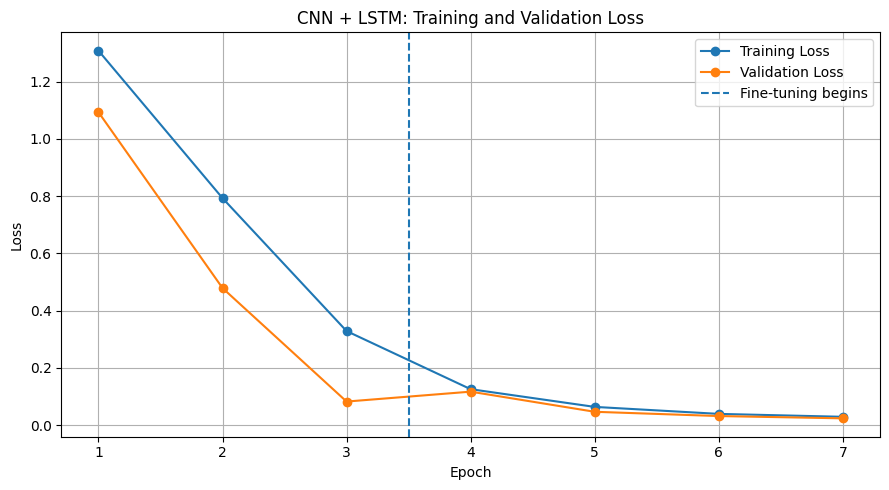

In [11]:
# Extract baseline LSTM history
baseline_history = all_histories["LSTM_8"]

frozen_train_loss = baseline_history["frozen"]["train_loss"]
frozen_val_loss = baseline_history["frozen"]["val_loss"]

finetune_train_loss = baseline_history["fine_tune"]["train_loss"]
finetune_val_loss = baseline_history["fine_tune"]["val_loss"]

# Combine the two stages
train_losses = frozen_train_loss + finetune_train_loss
val_losses = frozen_val_loss + finetune_val_loss

epochs = range(1, len(train_losses) + 1)

# Plot loss
plt.figure(figsize=(9, 5))
plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

# Mark the start of fine-tuning
plt.axvline(
    len(frozen_train_loss) + 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN + LSTM: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "lstm_loss_curves.png"),
    dpi=300
)
plt.show()

Interpretation:
- Both losses are decreasing meaning that the model is learning.


### 9.1 LSTM vs GRU vs Plain RNN

We will now compare test accuracy for the three recurrent architectures.

All three models use eight frames, so the main experimental difference is the recurrent unit.

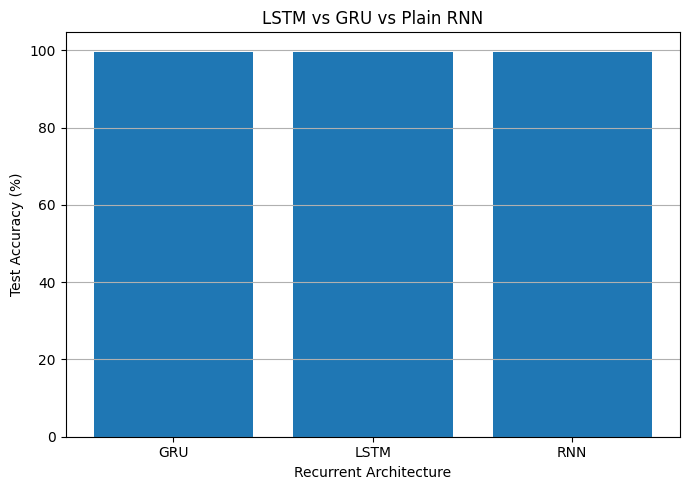

In [12]:
cell_comparison = results_df[
    results_df["frames"] == 8
].sort_values("recurrent_unit")

plt.figure(figsize=(7, 5))
plt.bar(
    cell_comparison["recurrent_unit"],
    cell_comparison["test_accuracy_percent"]
)
plt.xlabel("Recurrent Architecture")
plt.ylabel("Test Accuracy (%)")
plt.title("LSTM vs GRU vs Plain RNN")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "recurrent_architecture_comparison.png"),
    dpi=300
)
plt.show()

### 9.2 Effect of Number of Frames

We will investigate whether increasing the number of sampled frames improves classification accuracy.

We compare the LSTM models trained using 4, 8 and 16 frames.

More frames provide additional temporal information, but they can also increase computation and training time.

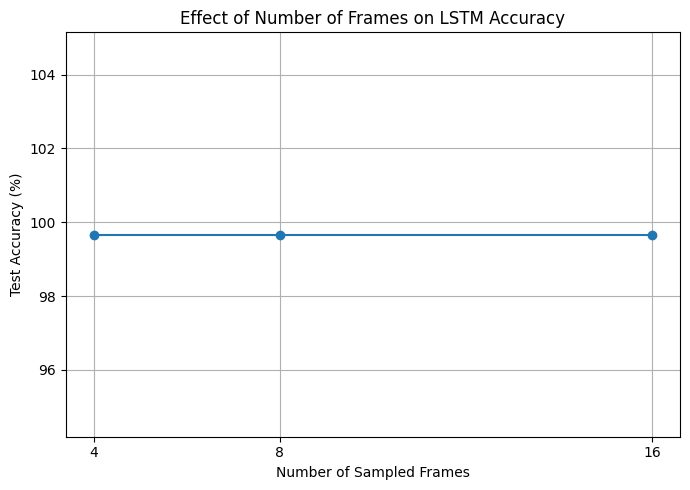

In [13]:
frame_comparison = results_df[
    results_df["recurrent_unit"] == "LSTM"
].sort_values("frames")

plt.figure(figsize=(7, 5))
plt.plot(
    frame_comparison["frames"],
    frame_comparison["test_accuracy_percent"],
    marker="o"
)
plt.xlabel("Number of Sampled Frames")
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Number of Frames on LSTM Accuracy")
plt.xticks([4, 8, 16])
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "frame_count_comparison.png"),
    dpi=300
)
plt.show()

## 10. Confusion Matrix and Failure Cases

We will use the baseline LSTM model trained with eight frames.

First, we generate predictions on the test dataset and create a confusion matrix.

The confusion matrix will help us identify which movement directions the model predicts correctly and which directions it confuses.

We will then visualise two incorrectly classified examples.

Baseline LSTM Test Accuracy: 0.9967


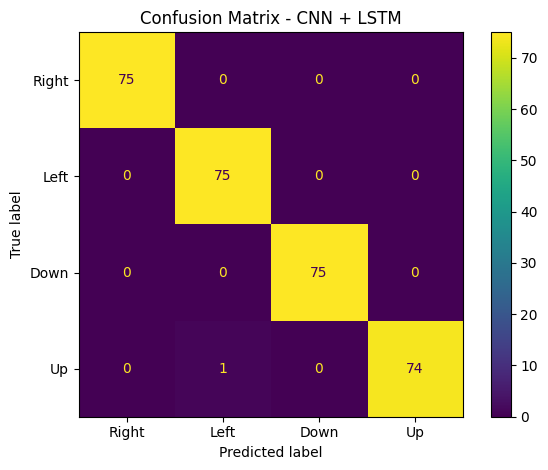

In [14]:
# Get the baseline model
baseline_model = trained_models["LSTM_8"]

# Create test loader with 8 frames
_, _, test_loader_8 = create_dataloaders(8)

# Evaluate
test_loss, test_accuracy, y_true, y_pred = evaluate(
    baseline_model,
    test_loader_8
)
print("Baseline LSTM Test Accuracy:", round(test_accuracy, 4))

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)
display.plot(values_format="d")
plt.title("Confusion Matrix - CNN + LSTM")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300
)
plt.show()

### 10.1 Inspecting Model Failures

A confusion matrix tells us where the model makes mistakes, but it does not show us the actual sequences behind those mistakes.

We will identify two incorrectly classified test examples and visualise their eight frames.

This will help us discuss what the model might have missed.

Number of incorrect predictions: 1


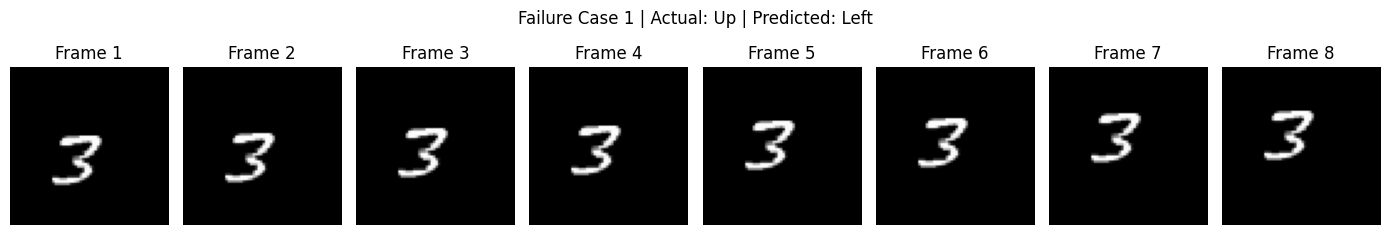

In [15]:
# Find misclassified test examples
y_true_array = np.array(y_true)
y_pred_array = np.array(y_pred)

wrong_indices = np.where(
    y_true_array != y_pred_array
)[0]

print("Number of incorrect predictions:", len(wrong_indices))

# Visualise two failure cases
test_dataset_8 = MovingMNISTDataset(
    X_test,
    y_test,
    num_frames=8
)

if len(wrong_indices) == 0:
    print(
        "No misclassified examples were found. "
        "Inspect low-confidence predictions or use a more challenging test set."
    )

else:
    for position, sample_index in enumerate(wrong_indices[:2]):
        frames, true_label = test_dataset_8[sample_index]
        predicted_label = y_pred_array[sample_index]
        fig, axes = plt.subplots(
            1,
            frames.shape[0],
            figsize=(14, 2.5)
        )
        for frame_number, ax in enumerate(axes):
            ax.imshow(
                frames[frame_number, 0].numpy(),
                cmap="gray"
            )
            ax.set_title(f"Frame {frame_number + 1}")
            ax.axis("off")

        fig.suptitle(
            f"Failure Case {position + 1} | "
            f"Actual: {CLASS_NAMES[true_label.item()]} | "
            f"Predicted: {CLASS_NAMES[predicted_label]}",
            fontsize=12
        )
        plt.tight_layout()
        plt.show()

## 11. Exporting Results

The final section saves the experiment results, plots and baseline LSTM model.

These files will be useful when preparing the assignment report.

We save:
- Results table as CSV.
- Baseline LSTM model weights.
- Loss curves.
- Recurrent architecture comparison plot.
- Frame-count comparison plot.
- Confusion matrix.

In [16]:
# Save experiment results
results_path = os.path.join(
    OUTPUT_DIR,
    "experiment_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# Save baseline LSTM model
baseline_model = trained_models["LSTM_8"]
checkpoint = {
    "model_state_dict": {
        key: value.cpu()
        for key, value in baseline_model.state_dict().items()
    },
    "recurrent_unit": "LSTM",
    "number_of_frames": 8,
    "hidden_size": 96,
    "class_names": CLASS_NAMES,
    "canvas_size": CANVAS_SIZE
}

model_path = os.path.join(
    OUTPUT_DIR,
    "baseline_lstm_model.pth"
)

torch.save(
    checkpoint,
    model_path
)

# Display exported files
print("Saved files:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

Saved files:
- experiment_results.csv
- confusion_matrix.png
- recurrent_architecture_comparison.png
- frame_count_comparison.png
- lstm_loss_curves.png
- baseline_lstm_model.pth
